In [ ]:
# import block:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, f1_score
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
from google.colab import files
uploaded = files.upload()



Saving Event_occurrence_matrix_weblog.csv to Event_occurrence_matrix_weblog.csv


In [ ]:
df = pd.read_csv('Event_occurrence_matrix_weblog.csv')
df.head()

,BlockId,Label,Type,E1,E2,E3,E4,E5,E6,E7,...,E20,E21,E22,E23,E24,E25,E26,E27,E28,E29
0,blk_-1608999687919862906,Success,NaN,0,0,203,0,10,7,0,...,0,10,1,10,0,4,10,0,0,0
1,blk_7503483334202473044,Success,NaN,0,2,1,0,3,0,0,...,0,3,1,3,0,0,3,0,0,0
2,blk_-3544583377289625738,Fail,21.0,0,0,203,0,3,0,0,...,1,3,1,3,0,0,3,0,0,0
3,blk_-9073992586687739851,Success,NaN,0,3,0,0,3,0,0,...,0,3,1,3,0,0,3,0,0,0
4,blk_7854771516489510256,Success,NaN,0,3,1,15,3,0,0,...,0,3,1,3,0,0,3,0,0,0


In [ ]:
df.Label.value_counts() # to check the no of success and failure

,count
Label,
Success,558223
Fail,16838


In [ ]:
# Separating Normal and Anomaly Samples
df['Label'] = df['Label'].map({'Success': 0, 'Fail': 1})
normal_data = df[df['Label'] == 0]  # label with success
anomaly_data = df[df['Label'] == 1]  # label with fail

print("Before undersampling:")
print(f"Normal: {len(normal_data)}, Anomaly: {len(anomaly_data)}")


Before undersampling:
Normal: 558223, Anomaly: 16838


In [ ]:
#since dataset has imbalanced data:
normal_sampled = normal_data.sample(n=len(anomaly_data)*2, random_state=42)

# Combine sampled normal data and all anomaly data
balanced_df = pd.concat([normal_sampled, anomaly_data], axis=0).sample(frac=1, random_state=42)  # shuffle


In [ ]:
# Get the label distribution after undersampling
label_counts = balanced_df['Label'].value_counts()

print("Label distribution after undersampling:")
print(f"Normal (0):  {label_counts.get(0, 0)}")
print(f"Anomaly (1): {label_counts.get(1, 0)}")


Label distribution after undersampling:
Normal (0):  33676
Anomaly (1): 16838


In [ ]:
X = balanced_df.drop(columns=['BlockId', 'Label', 'Type'], axis=1)
y = balanced_df['Label']

In [ ]:
# After loading the data:
df = pd.read_csv('Event_occurrence_matrix_weblog.csv')
print(f"Shape of df after loading: {df.shape}")


# Label: 'success' = 0 (normal); 'fail' = 1 (anomaly)
df['Label'] = df['Label'].map({'Success': 0, 'Fail': 1})


# Fill NaNs in event columns and type column (assume 0 for events, -1 or 'None' for type)
event_cols = [col for col in df.columns if col.startswith('E')]
df[event_cols] = df[event_cols].fillna(0)


# Before train-test split:
print(f"Shape of X before split: {X.shape}")
print(f"Shape of y before split: {y.shape}")

# Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


Shape of df after loading: (575061, 32)
Shape of X before split: (50514, 29)
Shape of y before split: (50514,)


In [ ]:
# Apply XGB Classifier:

model = XGBClassifier(
    max_depth=2,
    learning_rate=0.05,
    n_estimators=20,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='logloss',
    scale_pos_weight=3,
    random_state=42,
    reg_alpha=0.1,
    reg_lambda=1.0
)



In [ ]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)




/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [15:51:11] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


In [ ]:
# Calculating metrics:

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Display metrics

print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))


Precision: 0.9938
Recall: 0.9112
F1 Score: 0.9507


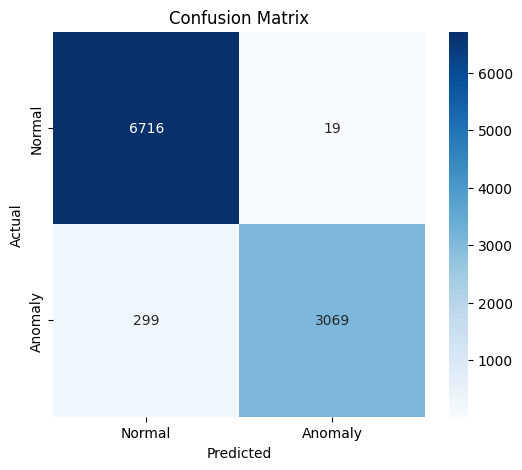

In [ ]:
# Make the confusion matrix
cm = confusion_matrix(y_test, y_pred)

#Display matrix

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Normal", "Anomaly"],
            yticklabels=["Normal", "Anomaly"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()
